# 🧾 Reading the Rap Sheet

*A small model learns to read one county's charge text. Calibration and a per-class abstention threshold
decide which calls it gets to make on its own.*

This notebook is the narrator, not the engine. The engine lives in the `rapsheet` package next door: each
cell here calls one piece of it, shows you what came back, and explains why the step exists at all. Any
number that ends up in the article comes out of a cell below and gets written into a run manifest, so
future me can't quietly round it up.

**📚 The route**

| § | Step | Why it's here |
| :--- | :--- | :---|
| 🧰 0 | Setup | Know which Python, torch and transformers produced these numbers |
| 🔄 0b | Fresh pull (optional) | Re-download the table on purpose; off by default |
| 🎣 1 | Pull | Get the table by query, so anyone can repeat it |
| 🛡️ 2 | Load, refuse, clean | Keep the columns we should use; refuse the ones we shouldn't |
| 🏷️ 3 | The label | Meet the categories before asking a model to learn them |
| 📜 4 | The disposition strings | See why 36 strings get a lookup instead of a model |
| ⛓️‍💥 5 | Splits | Make sure the test is actually a test |
| 🗃️ 5b | Snapshot | Freeze what we trained on, publicly and without identifiers |
| 🧪 6 | Baselines | Find out what a dictionary and a statute book already get right |
| 🧬 7 | Encoder | Fine-tune `legal-bert-small` on title + citation; same table, same rules |
| 🔁 7b | The rerun | Same fine-tune with class-tempered draws, so small categories get enough looks |
| 🌡️ 8 | Calibrate, abstain, draw | Make confidence honest, then let the model act alone only where it has earned it |
| 🪪 9 | Model card | Write the card from the manifest; publish the model on purpose |
| 📦 | Details | Every package, what it does, and why it's here |

**🗃️ The data.** Cook County State's Attorney *Dispositions* (dataset `apwk-dzx8` on the county's open-data
portal): public domain, about 1.08 million charge-level rows, de-identified by the publisher. We classify
charge *text*. Nothing here tries to work out who a record belongs to, and none of it is a screening tool.

**🧊 "Frozen," with an asterisk.** The publisher stopped maintaining the table in December 2024, yet the
portal's row timestamps were last touched in April 2026. So reproducibility rests on the manifest (query,
row counts, timestamps, seeds) rather than on the word *frozen*.

**📐 House style.** The package is classes only, one class per file, immutable dataclasses, one exit per
method, and not a single `return` keyword. If a method looks like it forgot to return something, it didn't:
the last expression *is* the return value. That's `modgud` at work; more in 📦 Details.

## 🧰 0 · Setup

⚙️ **What:** imports, paths, and a one-line receipt of the Python, torch and transformers versions, plus
whether the Mac's GPU (MPS) is visible.

🧭 **Why:** a fine-tuning result without its versions attached is an anecdote. `ROOT` assumes the notebook runs
from `notebooks/`; set `RAPSHEET_ROOT` if you run it from somewhere else.

🗝️ `HF_USERNAME` in `.env` names the Hugging Face account everything publishes to. `HubRepos` turns it into
the two repo ids and URLs used below, so the account name is written down in exactly one place, and it
isn't this notebook.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import sys
import torch
import transformers
from IPython.display import Image, Markdown, display

from rapsheet.baselines import MajorityBaseline, StatuteRulesBaseline, TfidfBaseline, TitleLookupBaseline
from rapsheet.cli import PullCommand
from rapsheet.core import Columns, RunManifest
from rapsheet.dataset import DatasetSplits, DispositionMap, DispositionsDataset, LabelSpace
from rapsheet.encoder import EncoderClassifier, EncoderConfig
from rapsheet.evaluation import ConfusionTable, HeadlineMetrics, LogitStore, SelectiveEvaluator, TemperatureCalibrator
from rapsheet.figures import FigureWriter
from rapsheet.ingest import SodaClient
from rapsheet.publish import HubPublisher, HubRepos, HubSnapshot, ModelCard

pd.set_option('display.max_rows', 120)
pd.set_option('display.width', 140)
pd.set_option("display.notebook_repr_html", False)

ROOT = Path(os.environ.get('RAPSHEET_ROOT', '..')).resolve()
RAW = ROOT / 'data' / 'raw'
PROCESSED = ROOT / 'data' / 'processed'
SNAPSHOT = ROOT / 'data' / 'snapshot'
MODELS = ROOT / 'models'
HUB = HubRepos.from_env()  # HF_USERNAME from .env; every Hub repo id and URL below comes from here
COLS = Columns()
print(f"Running on python kernel: {sys.version}")
print('torch', torch.__version__, 'transformers', transformers.__version__, 'mps', torch.backends.mps.is_available())
print('Hub namespace:', HUB.username, '→', HUB.dataset_id, '·', HUB.model_id)


Running on python kernel: 3.13.16 (main, Sep 30 2026, 18:57:20) [Clang 21.0.0 (clang-2100.3.34.2)]
torch 2.14.1 transformers 5.20.2 mps True


## 🔄 0b · Optional: throw out the cache and pull again

⚙️ **What:** with `FORCE_PULL = True`, this cell runs `PullCommand.main`, the same code behind
`poetry run rapsheet-pull --force`. It re-downloads all 22 pages from the portal, overwrites the parquet
and its manifest in `data/raw/`, and prints the cleaning counts, the category table and the
disposition-map coverage, so you can eyeball the new data before anything trains on it. The paths are
spelled out because the CLI's defaults assume the project root, and this notebook runs from `notebooks/`.

🧭 **Why it's off by default:** §1 already reuses the cache, and almost every run should. A fresh pull is
a new dataset: a new manifest, maybe new row counts, and every split, score and figure below moves with
it. The article's numbers belong to the manifest they came from. I'd rather change them on purpose than
because "Run All" is a reflex.

🧭 **When to flip it on:**
- 🛰️ **The source moved.** The dataset page on the portal shows an update newer than the
  `source_updated_at` that §1 prints. The publisher stopped maintaining this table in December 2024, so
  this should be rare. "Should" is doing some work in that sentence; see the April 2026 timestamps.
- 🐞 **The cache looks wrong.** The parquet won't load, or the manifest's reported and received row
  counts disagree.
- 🧪 **You're checking that it reproduces from scratch**, not just from my laptop's disk.

Then set it back to `False` and run everything below it. The splits, the baselines, the encoder and (if
you publish) the snapshot all need to meet the new data.

In [2]:
FORCE_PULL = False  # flip on purpose: re-downloads the table, and every number below moves with it

if FORCE_PULL:
  # Same code as `poetry run rapsheet-pull --force`. Paths are explicit because the CLI's defaults
  # are relative to the project root, and this notebook runs from notebooks/.
  PullCommand.main(['--force', '--cache-dir', str(RAW), '--map', str(ROOT / 'data' / 'disposition_map.yaml')])
else:
  print(f'FORCE_PULL is False; §1 will reuse the cached pull in {RAW.relative_to(ROOT)}/')

FORCE_PULL is False; §1 will reuse the cached pull in data/raw/


## 🎣 1 · Pull the table (or reuse the cache)

⚙️ **What:** `SodaClient.pull` asks the portal for fifteen named columns, 50,000 rows a page, and writes a
parquet file plus a manifest. If both already exist, it skips the network entirely.

🧭 **Why the details matter:**
- 🔢 **`$order=:id`.** Paging without a stable sort order can hand you one row twice and skip another.
  Ordering by the row id makes page 14 mean the same thing every time.
- 🧩 **Named columns only.** The protected columns are never requested. It's hard to leak what you
  never downloaded.
- 🗝️ **App token.** Put `SODA_APP_TOKEN=...` in the gitignored `.env` at the project root. `poetry-dotenv-plugin`
  loads it automatically for every `poetry run`, so launch with `poetry run jupyter lab` and the kernel inherits it.
  The token never lands in a notebook or a commit, and it keeps the portal from throttling a 22-page pull.
  Without one the pull still works, just more slowly.
- 🧾 **Manifest.** Rows the portal *reported* next to rows we *received*, plus the source's last-updated
  stamp. If those two counts ever disagree, I'd like to hear about it here and not from a reviewer.

In [3]:
client = SodaClient(app_token=os.environ.get('SODA_APP_TOKEN'))
parquet_path = client.pull(COLS.used, RAW)
manifest = RunManifest.read(RAW / f'{client.dataset_id}.manifest.json')
{k: manifest.to_dict()[k] for k in ('source_updated_at', 'retrieved_at', 'row_count_reported', 'row_count_fetched', 'page_count', 'git_sha', 'hardware')}

{'source_updated_at': '2026-04-02T14:58:19.622Z',
 'retrieved_at': '2026-10-20T19:13:38.872173+00:00',
 'row_count_reported': 1080014,
 'row_count_fetched': 1080014,
 'page_count': 22,
 'git_sha': '1789c71',
 'hardware': 'Darwin arm64 (arm) / Python 3.13.16'}

## 🛡️ 2 · Load, refuse, clean

Three steps, each with a reason.

1. 🛡️ **Refuse.** `load` raises an error if a protected column (`race`, `gender`, `age_at_incident`, `judge`,
   `incident_city`, `law_enforcement_agency`, `unit`) or the leakage column (`offense_category`, the label
   *before* the prosecutor's office updated it) is present. 🧭 *Why:* we never request them, but "we never
   request them" is a promise. The error turns the promise into a check.
2. 🔖 **One row per charge.** Keep `primary_charge == true` and only the latest `charge_version_id` for each
   `charge_id`. 🧭 *Why:* charges get amended over their lives. Training on every version would count the
   same charge several times and teach the model the history of the paperwork.
3. 🔤 **Normalize titles, gently.** Trim, collapse whitespace, upper-case, and leave the punctuation alone.
   🧭 *Why:* in this vocabulary `<$300` and `>$300` are different crimes. Strip the symbols and you merge them.

🏚️ Then one exclusion. **`PROMIS Conversion`** is a value in the label column, but it isn't an offense. It
marks records migrated from the county's legacy case system, nearly all received between 1984 and 2010. The
titles on those rows are real charges, so training on them would teach the model that
`MURDER/INTENT TO KILL/INJURE` means both *Homicide* and *PROMIS Conversion*. They go aside rather than in
the bin, because they come back in §3 as a drift probe.

In [4]:
dataset = DispositionsDataset(min_class_rows=20, rare_title_max=5, temporal_cutoff='2023-01-01', seed=42)
raw = dataset.load(parquet_path)
cleaned = dataset.clean(raw)
set_aside = dataset.excluded_rows(raw)
print('excluded labels:', dataset.excluded_labels, f'→ {len(set_aside):,} rows set aside')
cleaned.attrs['cleaning']

excluded labels: ('PROMIS Conversion',) → 9,824 rows set aside


{'loaded': 1080014,
 'primary_charge': 377364,
 'latest_charge_version': 362846,
 'with_title_and_label': 362846,
 'label_excluded': 9824,
 'after_label_exclusion': 353022}

## 🏷️ 3 · The label: `updated_offense_category`

⚙️ **What:** a group-by on the label, after cleaning.

🧭 **Why:** before asking a model to learn these categories, I'd like to know what they are and how lopsided
they get. Very lopsided, as it turns out. *Narcotics* alone is a little over a third of the rows, so a
"model" that always answers *Narcotics* already gets a third right. That's the floor every real model here
has to clear, and it goes in the headline table so nobody (me included) gets excited about 40%. At the
other end of the list sits a category with one row. One.

In [5]:
categories = dataset.category_counts(cleaned)
print(f'{len(categories)} distinct categories across {len(cleaned):,} primary charges')
categories

77 distinct categories across 353,022 primary charges


                                                 rows   share
updated_offense_category                                     
Narcotics                                      131030  0.3712
UUW - Unlawful Use of Weapon                    52928  0.1499
Aggravated DUI                                  20719  0.0587
Retail Theft                                    20222  0.0573
Burglary                                        13036  0.0369
Driving With Suspended Or Revoked License       12583  0.0356
Aggravated Battery Police Officer                8964  0.0254
Theft                                            8549  0.0242
Possession of Stolen Motor Vehicle               6538  0.0185
Residential Burglary                             6333  0.0179
Sex Crimes                                       6174  0.0175
Armed Robbery                                    5552  0.0157
Other Offense                                    4955  0.0140
Escape - Failure to Return                       4743  0.0134
Robbery 

### 🔤 How open is the "open" vocabulary?

⚙️ **What:** `title_stats` counts distinct titles, the titles that carry more than one label, and the
**title-majority ceiling**: the share of rows whose label matches the most common label for their title.

🧭 **Why:** this is the number that keeps the article honest. The pitch says charge titles are an open
vocabulary, which makes them a job for a model. But if a little over a thousand titles cover every row,
and each title almost always gets the same label, a dictionary does most of the work. (Spoiler: about 95% of it.) The ceiling is the
most *any* title-only classifier can score on titles it has already seen; the model earns its keep on the
ones it hasn't. I'd rather learn that here than in an interview.

In [6]:
title_stats = dataset.title_stats(cleaned)
title_stats

{'rows': 353022,
 'titles': 1365,
 'multi_label_titles': 391,
 'rows_on_multi_label_titles': 333066,
 'title_majority_ceiling': 0.9537}

### 🏚️ The set-aside rows: a legacy dialect

⚙️ **What:** the `PROMIS Conversion` rows set aside in §2, checked against every title in the labeled data.

🧭 **Why:** some of them use titles the labeled data never does. `MANUE/DEL 01-15 GR COCAINE/ANLG` is cocaine
manufacture/delivery spelled the way an older system spelled it. That's format drift inside a single
county, which the original plan said this dataset couldn't show. There's no usable label on these rows, so
accuracy is off the table, and that's fine: a well-calibrated model should abstain more often on
them. Coverage drops before accuracy does, and coverage doesn't need labels.

In [7]:
promis_unseen = dataset.unseen_titles(set_aside, cleaned)
print(f'{len(set_aside):,} set-aside rows; received', set_aside[COLS.RECEIVED_DATE].dt.year.min(), '→', set_aside[COLS.RECEIVED_DATE].dt.year.max())
print(f'{int(promis_unseen.sum()):,} rows ({promis_unseen.mean():.1%}) carry titles never seen with a real label')
set_aside.loc[promis_unseen, COLS.TITLE].value_counts().head(12)

9,824 set-aside rows; received 1901 → 2012
4,833 rows (49.2%) carry titles never seen with a real label


disposition_charged_offense_title
POSS AMT CON SUB EXCEPT (A)/(D)                       736
ARMED ROBBERY ARMED W/FIREARM                         226
MANUE/DEL 01-15 GR COCAINE/ANLG                       155
RET THEFT/DISPLAY MERCH/>$150                         154
MFG/DEL CONTROLLED SUBSTANCE                          122
AGG BATT/HARM/PEACE OFFICER                           118
RECEIVE POSS/SELL STOLEN VEH                           86
REVOKED/SUSPENDED 2ND+ DUI                             72
AMT NARC SCHED I/II/SCH/HS/PK                          68
ARMED ROBBERY/NO FIREARM/FINDING GREAT BODILY HARM     68
FORGERY/MAKE/ALTER DOCUMENT                            68
MANUE/DEL 1-15 GR HEROIN/ANALOG                        63
Name: count, dtype: int64[pyarrow]

## 📜 4 · Thirty-six disposition strings → `disposition_map.yaml` v1

⚙️ **What:** map every raw `charge_disposition` string to one of five outcomes (convicted, acquitted, not
prosecuted, vacated, not final) with a hand-written, versioned YAML file, then report anything it doesn't
recognize.

🧭 **Why a lookup and not a model:** there are exactly 36 strings, and a person can read all of them in ten
minutes. My favorite is *Finding Not Not Guilty*, 2,437 rows of it, which a human decodes in half a second
as *not guilty*. When someone disputes what their record says, they're owed a rule with a version number,
not a confidence score. ⚖️ **Rules are not weights.**

🧭 **Why report instead of guess:** a lookup that guesses is a model with worse documentation. The flagged
strings at the bottom are the ones I still have to confirm before anything is published.

In [8]:
disposition_map = DispositionMap.from_yaml(ROOT / 'data' / 'disposition_map.yaml')
raw_dispositions = raw[COLS.DISPOSITION].value_counts()
print(f'{len(raw_dispositions)} raw strings; map v{disposition_map.version} knows {len(disposition_map.vocabulary)}')
display(disposition_map.coverage(raw[COLS.DISPOSITION]))
unmapped = disposition_map.unmapped(raw[COLS.DISPOSITION])
print('unmapped:', 'none' if unmapped.empty else unmapped.to_dict())
disposition_map.flagged()

36 raw strings; map v1 knows 36


                      rows   share
charge_disposition                
not_prosecuted      717037  0.6639
convicted           301036  0.2787
acquitted            50544  0.0468
non_final            11224  0.0104
vacated                173  0.0002

unmapped: none


                      raw      class                                               note
0                     BFW  non_final  bond forfeiture warrant — status, not an adjud...
1                    WOWI  non_final                  confirm meaning before publishing
2                TRAN-FAI  non_final                                single row; confirm
3     FNG Reason Insanity  acquitted  acquittal by reason of insanity — kept under a...
4  Finding Not Not Guilty  acquitted  data-entry artifact meaning not guilty; kept u...

## ⛓️‍💥 5 · Splits: make the test a test

⚙️ **What:** four frames.
- 🕰 **Temporal hold-out:** everything received on or after 2023-01-01, set aside first.
- 🧪 **Train / val / test:** the rest, split roughly 80/10/10 with `StratifiedGroupKFold`. Stratified, so
  rare categories show up in every split; grouped by `case_id`, so no case lands on both sides of the line.

🧭 **Why group by case:** charges in the same case share titles, dates and often wording. Spread them across
train and test, and the model gets graded on homework it has already seen. The `assert` below fails if any
`case_id` crosses a split.

🧭 **Why a temporal set:** new statutes bring new titles. Scoring on 2023–2024 cases is the most honest "the
world moved on" test one county can offer.

**Two more flags:**
- 🗂️ Categories with fewer than 20 training rows are folded into `(rare, folded)` for training. Their real
  names stay in `label`, so the table below can still report them. The bucket isn't called *Other* because
  the prosecutor's taxonomy already has an `Other Offense`, and two "others" in one confusion matrix is one
  too many.
- 🚨 `rare_title` marks rows whose title appears fewer than five times in training. That slice is where the
  drift alarm will (or won't) go off.

This cell takes a minute or two at full scale. That's `StratifiedGroupKFold` doing its bookkeeping in plain
Python, not your laptop giving up.

In [9]:
print("Splitting cleaned data...")
splits = dataset.split(cleaned)
print("Performing leakage check...")
assert splits.leakage_check(), 'a case_id crosses splits'
print(f'folded into {splits.folded_label!r}:', splits.folded_classes)
print('training label space:', len(splits.label_names))
splits.summary()

Splitting cleaned data...
Performing leakage check...
folded into '(rare, folded)': ('Arson and Attempt Arson', 'Battery', 'DUI', 'Dog Fighting', 'Gambling', 'Pandering', 'Perjury', 'Possession of Explosives', 'Tampering', 'Violation of Sex Offender Registration')
training label space: 68...
folded into '(rare, folded)': ('Arson and Attempt Arson', 'Battery', 'DUI', 'Dog Fighting', 'Gambling', 'Pandering', 'Perjury', 'Possession of Explosives', 'Tampering', 'Violation of Sex Offender Registration')



            rows   cases  titles  labels  rare_title_rows min_received max_received
split                                                                              
train     266439  259762    1229      77             1191   1979-11-20   2022-12-31
val        33305   32470     574      74              175   1996-12-17   2022-12-31
test       33305   32471     593      75              190   1979-08-23   2022-12-31
temporal   19973   19367     414      64              141   2023-01-01   2024-11-22

### 🔬 The categories we folded

⚙️ **What:** row counts in each split for every folded category.

🧭 **Why:** folding is a small act of giving up, and I'd like the receipts. The model can't learn these
categories by name, so the article lists them by name instead of letting them disappear into an average.

In [10]:
splits.rare_class_table()

                                        train  val  test  temporal
label                                                             
Battery                                    16    2     2         0
Gambling                                   15    2     2         0
Perjury                                    15    2     2         0
Dog Fighting                               14    2     2         0
Pandering                                  10    2     1         0
DUI                                         7    1     1         0
Arson and Attempt Arson                     4    1     1         0
Tampering                                   4    0     1         5
Possession of Explosives                    3    0     0         0
Violation of Sex Offender Registration      1    0     0         0

### 📍 Write it down

⚙️ **What:** save the four splits as parquet and extend the run manifest with the seed, cleaning counts, label
policy, title stats and split sizes.

🧭 **Why:** The training cells read these files, not this notebook's memory, and every number in the
article has to trace back to `data/processed/manifest.json`.

In [11]:
out = splits.write(PROCESSED)
manifest.with_seeds(split=splits.seed).with_config(
  cleaning=cleaned.attrs['cleaning'],
  min_class_rows=dataset.min_class_rows,
  rare_title_max=dataset.rare_title_max,
  temporal_cutoff=dataset.temporal_cutoff,
  n_categories=int(len(categories)),
  folded_classes=list(splits.folded_classes),
  folded_label=splits.folded_label,
  excluded_labels=list(dataset.excluded_labels),
  split_rows={k: len(v) for k, v in splits.frames.items()},
  title_stats=title_stats,
  set_aside_rows=len(set_aside),
  set_aside_unseen_title_rows=int(promis_unseen.sum()),
  processed_on=RunManifest.current_hardware(),
  processed_git_sha=RunManifest.current_git_sha(),
).write(PROCESSED / 'manifest.json')

PosixPath('/Users/windfox/src/rapsheet/data/processed/manifest.json')

### 🗃️ 5b · Snapshot: freeze what we trained on

⚙️ **What:** write the four splits, plus the set-aside PROMIS rows, as a Hugging Face dataset folder in
`data/snapshot/`: one parquet per split and a dataset card (`README.md`) whose numbers come from the
manifest. Only the columns the models use are kept; case, participant and charge identifiers stay
home.

🧭 **Why:** the source table is unmaintained, and its row timestamps have already moved once since it
was "frozen." The manifest can prove what we pulled, but it can't bring the data back if the portal
changes. A public snapshot can. And since nothing after the split needs an identifier, publishing
one would be all risk and no reward.

In [12]:
processed_manifest = RunManifest.read(PROCESSED / 'manifest.json')
snapshot = HubSnapshot(repo_id=HUB.dataset_id)
snapshot_summary = snapshot.write(splits, set_aside, processed_manifest, SNAPSHOT)
processed_manifest.with_extra(snapshot=snapshot_summary).write(PROCESSED / 'manifest.json')
pd.Series(snapshot_summary['rows'], name='rows').to_frame()

                    rows
train             266439
validation         33305
test               33305
temporal           19973
promis_set_aside    9824

### 🛰️ Publish to the Hub (on purpose)

⚙️ **What:** push `data/snapshot/` to the public dataset repo `HUB.dataset_id`
(`<HF_USERNAME>/rapsheet-charge-titles`) through `HubPublisher`, the one class in the package that sends anything off this machine. It creates
the repo if needed, uploads the folder, and refuses a folder without a dataset card.

🧭 **Why it's guarded:** "Restart & Run All" is a reflex, and publishing shouldn't be. The cell does nothing
until you set `PUBLISH = True`, and it prints who it will publish as before it does.

**🗝️ One-time setup:** `HF_USERNAME=...` and `HF_TOKEN=...` (a token with write access) in `.env`, where
`poetry-dotenv-plugin` picks them up like the portal token. `HubPublisher` refuses to push to a namespace
the token doesn't own. From a shell, `poetry run rapsheet-publish dataset --yes` does the same push. The fine-tuned model goes
up the same way, with `repo_type='model'`.

In [13]:
PUBLISH = False  # flip on purpose: this makes the snapshot public on the Hugging Face Hub

if PUBLISH:
  publisher = HubPublisher()
  print('publishing as', publisher.identity(), 'to', HUB.dataset_url)
  print(publisher.publish(
    SNAPSHOT,
    HUB.dataset_id,
    message=f"Snapshot of the {processed_manifest.retrieved_at[:10]} pull (git {processed_manifest.config.get('processed_git_sha')})",
  ))
else:
  print(f'PUBLISH is False; {HUB.dataset_id} was not touched.')

publishing as terracoil
https://huggingface.co/datasets/terracoil/rapsheet-charge-titles


---
### 🏁 Monday checkpoint

Parquet cached, manifest written, class counts known. The baselines below are a head.

## 🧪 6 · Baselines: four cheap ways to be right (and wrong)

⚙️ **What:** four models that read charge text without a neural network, scored on the stratified test set
and the 2023+ temporal set.

| Baseline | What it sees | What it's for |
| :--- | :--- | :--- |
| 📊 Majority class | Nothing at all | The floor. Always answers *Narcotics*. |
| 📖 Title lookup | The title, as an exact string | The dictionary: whatever label that title usually got in training, and the prior for a title it has never met. |
| 📜 Statute rules | Chapter, act and section only (never the title) | The rule a lawyer could write down, backing off to a coarser citation when the exact one is new. |
| 🧮 TF-IDF + logistic regression | Word and character n-grams of the title | The classical model with a long record of embarrassing transformers on short, stylized text. |

🧭 **Why four, when the plan said two:** §3 showed the vocabulary is mostly closed, so the honest question
isn't "does the transformer beat TF-IDF?" It's "does anything beat a dictionary, and where?" A headline
table without the floor and the dictionary would flatter whoever wins it.

🧭 **Why this cell is fast:** 266k training rows hold only about 1,200 distinct titles. Every model here
trains on the distinct (title, label) pairs, weighted by how often each occurs. That's the same loss as
training on every row, since identical rows add identical terms, and it takes seconds instead of a coffee
break.

**📏 Reading the table:** *rare-class recall* averages recall over named categories with fewer than 500
training rows; *rare-title accuracy* is accuracy on rows whose title showed up fewer than five times in
training. Both are small slices, so treat them as directions, not decimals.

In [14]:
splits = DatasetSplits.read(PROCESSED)  # from disk on purpose: everything from here must work without the cells above
space = LabelSpace.from_splits(splits)
baselines = [
  model.fit(splits.train)
  for model in (
    MajorityBaseline(space),
    TitleLookupBaseline(space),
    StatuteRulesBaseline(space),
    TfidfBaseline(space, seed=splits.seed),
  )
]
print(f'{space.size} training labels; {len(space.rare_classes())} rare classes (< 500 training rows)')
headline = HeadlineMetrics(space).table(baselines, splits)
headline

68 training labels; 35 rare classes (< 500 training rows)


                                        rows  accuracy  macro_f1  rare_class_recall  rare_classes_scored  rare_title_rows  \
model                        split                                                                                          
majority class (floor)       test      33305    0.3748    0.0080             0.0000                   35              190   
                             temporal  19973    0.3097    0.0074             0.0000                   31              141   
title lookup                 test      33305    0.9520    0.8259             0.7478                   35              190   
                             temporal  19973    0.9428    0.8070             0.7068                   31              141   
statute rules                test      33305    0.9643    0.8607             0.7799                   35              190   
                             temporal  19973    0.9604    0.8383             0.7354                   31              141   


### 📜 How often does the statute book have an answer?

⚙️ **What:** the share of test and temporal rows whose most specific statute match is a section, an act, a
chapter, or nothing at all.

🧭 **Why:** a rule that only fires on part of the rows isn't losing on accuracy; it's losing on coverage.
That's a different argument, and it deserves its own number.

In [15]:
rules = baselines[2]
pd.DataFrame({name: rules.match_levels(splits.frames[name]) for name in ('test', 'temporal')}).fillna(0)

           test  temporal
act      0.0010    0.0017
chapter  0.0001    0.0001
none     0.0001    0.0001
section  0.9988    0.9981

### 🏚️ The dictionary meets the legacy dialect

⚙️ **What:** each baseline's average top-class confidence on the set-aside PROMIS rows whose titles never
appear with a real label, next to the same number on the test set.

🧭 **Why:** there are no labels on these rows, so there's no accuracy to report, but confidence still talks.
The lookup has never seen these titles and falls back to the prior, so it *can't* be confident. TF-IDF can
read `MANUE/DEL` about as easily as `MFG/DEL`, so it may well be confident, rightly or not. That gap is the
whole case for calibration.

In [16]:
probe = set_aside[promis_unseen.to_numpy()]
pd.DataFrame({
  model.name: {
    'test': float(model.predict_proba(splits.test).max(axis=1).mean()),
    'PROMIS, unseen titles': float(model.predict_proba(probe).max(axis=1).mean()),
  }
  for model in baselines
}).T.round(3).rename_axis('mean top-class confidence')

                               test  PROMIS, unseen titles
mean top-class confidence                                 
majority class (floor)        0.375                  0.375
title lookup                  0.950                  0.375
statute rules                 0.961                  0.410
TF-IDF + logistic regression  0.952                  0.716

### 📍 Write the headline down

⚙️ **What:** add the headline table and the statute match rates to `data/processed/manifest.json`.

🧭 **Why:** same rule as before: if a number makes it into the article, it lives in the manifest first.

In [17]:
RunManifest.read(PROCESSED / 'manifest.json').with_extra(
  baselines=headline.reset_index().to_dict('records'),
  statute_match_levels={name: rules.match_levels(splits.frames[name]) for name in ('test', 'temporal')},
).write(PROCESSED / 'manifest.json')


PosixPath('/Users/windfox/src/rapsheet/data/processed/manifest.json')

## 🧬 7 · The encoder: `legal-bert-small` reads the title *and* the citation

⚙️ **What:** fine-tune [`nlpaueb/legal-bert-small-uncased`](https://huggingface.co/nlpaueb/legal-bert-small-uncased)
(about 35M parameters, pretrained on legislation and court cases) with a fresh 68-way head. Each input is a
sentence pair, written the way Illinois writes its statutes:

`[CLS] AGG UUW/VEH/PREV CONVICTION [SEP] 720 ILCS 5/24-1.6 [SEP]`

Three epochs of 50,000 draws, AdamW, linear warm-up and decay; the epoch with the lowest *validation
negative log-likelihood* wins.

🧭 **Why the citation goes in:** §6 showed the statute book beats anything that reads only the title
(96.4% against a 95.4% ceiling). A title-only model can't win that column, by construction. Handing the
encoder both asks the fair question: does reading the words *and* the citation beat the rule that reads
the citation alone? (The disposition map stays a lookup either way. That argument was never about
accuracy.)

🧭 **Why draws instead of passes over rows:** the 266k training rows hold only a couple of thousand
distinct (title, citation) inputs. Each step draws inputs in proportion to how often they occur, which is
exactly the distribution of drawing rows, so 150k draws see the data the way 150k rows would, without
re-encoding the same string ten thousand times.

🧭 **Why a hand-written loop instead of `Trainer`:** the weighted draw is the whole trick, and thirty
lines of torch show it plainly. `Trainer` would hide it behind a subclass.

🧭 **Why NLL picks the epoch, not accuracy:** calibration comes next, and it rewards honest probabilities.
Choosing the epoch by NLL avoids the one that is most accurate *and* most overconfident.

⏱️ On an M-series Mac this is minutes, not hours. If an operation isn't supported on the Apple GPU,
`PYTORCH_ENABLE_MPS_FALLBACK=1` in `.env` lets it fall back to the CPU instead of stopping.

🔁 **Run All doesn't retrain.** With `RETRAIN = False`, the cell reloads the model §7 saved last time (same
weights, same history), so a full run costs minutes, not a coffee. Flip it to `True` to fine-tune again.

In [18]:
encoder_config = EncoderConfig(include_statute=True, seed=splits.seed)
encoder_dir = MODELS / 'rapsheet-legal-bert-small'
RETRAIN = True  # True = fine-tune again (~10 min on the Mac's GPU); False = reuse the model saved last time

if RETRAIN or not (encoder_dir / 'config.json').exists():
  print('training on', encoder_config.resolved_device())
  encoder = EncoderClassifier(space, encoder_config).fit(splits.train, splits.val)
else:
  encoder = EncoderClassifier.load(encoder_dir)
  print(f'reusing {encoder_dir.relative_to(ROOT)}/ (set RETRAIN = True to fine-tune again)')
pd.DataFrame(encoder.history).set_index('epoch')

training on mps


W1021 10:23:34.198000 79802 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: nlpaueb/legal-bert-small-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those

       train_loss  val_nll  val_accuracy  val_inputs
epoch                                               
1         0.75559  0.22272       0.95577         862
2         0.20796  0.19215       0.96064         862
3         0.18818  0.18166       0.96094         862

### 📊 The headline table, now with a neural network in it

⚙️ **What:** the same `HeadlineMetrics`, the same splits, five rows instead of four.

🧭 **Why it's the same call:** every model satisfies the same `Classifier` protocol, so the encoder gets no
special scoring and no second chance. If it can't beat the statute book here, it doesn't get to on a slide
either.

In [19]:
models = [*baselines, encoder]
headline = HeadlineMetrics(space).table(models, splits)
headline

                                              rows  accuracy  macro_f1  rare_class_recall  rare_classes_scored  rare_title_rows  \
model                              split                                                                                          
majority class (floor)             test      33305    0.3748    0.0080             0.0000                   35              190   
                                   temporal  19973    0.3097    0.0074             0.0000                   31              141   
title lookup                       test      33305    0.9520    0.8259             0.7478                   35              190   
                                   temporal  19973    0.9428    0.8070             0.7068                   31              141   
statute rules                      test      33305    0.9643    0.8607             0.7799                   35              190   
                                   temporal  19973    0.9604    0.8383             

### 🏚️ The encoder meets the legacy dialect

⚙️ **What:** the encoder's average top-class confidence on the PROMIS rows whose titles it has never seen,
next to the test set.

🧭 **Why:** no labels here, so no accuracy, only confidence. A model that's as sure of itself on
`MANUE/DEL 01-15 GR COCAINE/ANLG` as on titles it trained on is a model that needs a calibrator and an
abstention threshold before it decides anything.

In [20]:
pd.DataFrame({
  model.name: {
    'test': float(model.predict_proba(splits.test).max(axis=1).mean()),
    'PROMIS, unseen titles': float(model.predict_proba(probe).max(axis=1).mean()),
  }
  for model in models
}).T.round(3).rename_axis('mean top-class confidence')

                                     test  PROMIS, unseen titles
mean top-class confidence                                       
majority class (floor)              0.375                  0.375
title lookup                        0.950                  0.375
statute rules                       0.961                  0.410
TF-IDF + logistic regression        0.952                  0.716
legal-bert-small (title + statute)  0.962                  0.813

### 📍 Save the logits, the model, and the receipts

⚙️ **What:** raw logits for validation, test, temporal and the PROMIS probe go to `data/processed/logits/` (one `.npz`
each, with labels and rare-title flags alongside); the fine-tuned model goes to `models/`; the config,
the training history and the five-row headline go into the manifest.

🧭 **Why:** temperature scaling fits one number on the validation logits, and the risk–coverage curves
need test, temporal and the probe. With the logits on disk, the afternoon's work never retrains. The model
folder is gitignored: it's about 140 MB, and it goes to the Hub, not to git.

In [21]:
store = LogitStore.at(PROCESSED / 'logits')
evaluated = {'val': splits.val, 'test': splits.test, 'temporal': splits.temporal, 'promis_unseen': probe}
for name, frame in evaluated.items():
  store.save(name, frame, encoder.predict_logits(frame), space)
model_dir = encoder.save(encoder_dir)

RunManifest.read(PROCESSED / 'manifest.json').with_seeds(encoder=encoder_config.seed).with_extra(
  encoder={'config': encoder_config.to_dict(), 'history': list(encoder.history), 'saved_to': str(model_dir.relative_to(ROOT))},
  baselines=headline.reset_index().to_dict('records'),
  logits=list(store.names()),
).write(PROCESSED / 'manifest.json')
store.names()

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('promis_unseen', 'temporal', 'test', 'val')

## 🔁 7b · The rerun: class-tempered draws

⚙️ **What:** the same fine-tune with one switch flipped, `class_temper=0.5`. Each category gets drawn in
proportion to the *square root* of its size (inputs inside a category still come as often as they occur),
and the matching logit adjustment goes back in at prediction time, so the probabilities still answer for
the real class frequencies.

🧭 **Why:** §7 drew inputs in proportion to how often they occur. That's honest about the rows and stingy
with the small categories: three epochs of 50,000 draws give a 25-row category about 14 looks, and the
headline table showed what that costs. Square-root tempering gives that category about 280 looks, while
*Narcotics* still keeps a double-digit share of the draws.

🧭 **Why a second model instead of a replacement:** a fix you can't compare with the thing it fixed is an
anecdote. Both rows go in the table.

⏱️ About ten more minutes on the Mac's GPU, once. After that, `RETRAIN_TEMPERED = False` reuses it.

In [22]:
tempered_config = EncoderConfig(include_statute=True, class_temper=0.5, seed=splits.seed)
tempered_dir = MODELS / 'rapsheet-legal-bert-small-tempered'
RETRAIN_TEMPERED = False  # True = fine-tune again; the first run always trains

if RETRAIN_TEMPERED or not (tempered_dir / 'config.json').exists():
  print('training on', tempered_config.resolved_device())
  tempered = EncoderClassifier(space, tempered_config).fit(splits.train, splits.val)
else:
  tempered = EncoderClassifier.load(tempered_dir)
  print(f'reusing {tempered_dir.relative_to(ROOT)}/')
pd.DataFrame(tempered.history).set_index('epoch')

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

reusing models/rapsheet-legal-bert-small-tempered/


       train_loss  val_nll  val_accuracy  val_inputs
epoch                                               
1         1.19345  0.18637       0.96076         862
2         0.36562  0.16972       0.96319         862
3         0.33398  0.16305       0.96403         862

### 📊 Six rows: did the small categories show up?

⚙️ **What:** the headline table with both encoders, and the PROMIS confidence probe.

🧭 **Why:** the rare-class recall column is the one the rerun is for. Accuracy should barely move; if it
drops a lot, the tempering bought the small categories at the big ones' expense.

In [23]:
models = [*baselines, encoder, tempered]
headline = HeadlineMetrics(space).table(models, splits)
display(headline)
pd.DataFrame({
  model.name: {
    'test': float(model.predict_proba(splits.test).max(axis=1).mean()),
    'PROMIS, unseen titles': float(model.predict_proba(probe).max(axis=1).mean()),
  }
  for model in (encoder, tempered)
}).T.round(3).rename_axis('mean top-class confidence')

                                                              rows  accuracy  macro_f1  rare_class_recall  rare_classes_scored  \
model                                              split                                                                         
majority class (floor)                             test      33305    0.3748    0.0080             0.0000                   35   
                                                   temporal  19973    0.3097    0.0074             0.0000                   31   
title lookup                                       test      33305    0.9520    0.8259             0.7478                   35   
                                                   temporal  19973    0.9428    0.8070             0.7068                   31   
statute rules                                      test      33305    0.9643    0.8607             0.7799                   35   
                                                   temporal  19973    0.9604    0.8383    

                                                     test  PROMIS, unseen titles
mean top-class confidence                                                       
legal-bert-small (title + statute)                  0.962                  0.813
legal-bert-small (title + statute, class-temper...  0.968                  0.849

### 📍 Save the rerun, then compare what each encoder earns

⚙️ **What:** the tempered model's logits go to `data/processed/logits-tempered/`, the model to `models/`,
the receipts to the manifest. Then calibration and the 0.5% abstention policy run on both encoders' logits,
side by side.

🧭 **Why:** better rare-class recall only matters here if it changes what the model is *allowed* to decide.
Small categories still need roughly 540 clean validation calls to earn a threshold, so don't expect the
autonomy table to grow much. Expect the mistakes it routes to people to get better.

In [24]:
tempered_store = LogitStore.at(PROCESSED / 'logits-tempered')
for name, frame in evaluated.items():
  tempered_store.save(name, frame, tempered.predict_logits(frame), space)
tempered_model_dir = tempered.save(tempered_dir)

RunManifest.read(PROCESSED / 'manifest.json').with_extra(
  encoder_tempered={
    'config': tempered_config.to_dict(),
    'history': list(tempered.history),
    'saved_to': str(tempered_model_dir.relative_to(ROOT)),
  },
  baselines=headline.reset_index().to_dict('records'),
  probe_confidence={m.name: float(m.predict_proba(probe).max(axis=1).mean()) for m in (encoder, tempered)},
).write(PROCESSED / 'manifest.json')

comparison = {}
for label, logit_dir in ((encoder.name, 'logits'), (tempered.name, 'logits-tempered')):
  saved_logits = {name: LogitStore.at(PROCESSED / logit_dir).load(name) for name in ('val', 'test', 'temporal', 'promis_unseen')}
  truth = {name: saved['labels'] for name, saved in saved_logits.items()}
  scaler = TemperatureCalibrator().fit(saved_logits['val']['logits'], truth['val'])
  calibrated = {name: scaler.probabilities(saved['logits']) for name, saved in saved_logits.items()}
  judge = SelectiveEvaluator(space, error_budget=0.005)
  taus = judge.class_thresholds(calibrated['val'], truth['val'])
  one_tau = judge.global_threshold(calibrated['val'], truth['val'])
  row = {'T': scaler.temperature, 'ece_test': scaler.report(saved_logits['test']['logits'], truth['test'])['ece_after'],
         'classes_earned': int(np.isfinite(taus).sum())}
  for name in ('test', 'temporal', 'promis_unseen'):
    summary = judge.summary(calibrated[name], truth[name], taus, one_tau)
    row |= {f'{name}_alone': summary['per_class_coverage'], f'{name}_error': summary['per_class_error']}
  comparison[label] = row
pd.DataFrame(comparison).T

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

                                                           T  ece_test  classes_earned  test_alone  test_error  temporal_alone  \
legal-bert-small (title + statute)                  0.963171    0.0072             3.0      0.1427      0.0034          0.0700   
legal-bert-small (title + statute, class-temper...  1.001557    0.0048             3.0      0.1415      0.0032          0.0693   

                                                    temporal_error  promis_unseen_alone  promis_unseen_error  
legal-bert-small (title + statute)                          0.0143               0.0555                  NaN  
legal-bert-small (title + statute, class-temper...          0.0145               0.0387                  NaN  

## 🌡️ 8 · Calibration: does 90% confident mean 90% right?

⚙️ **What:** fit one number, the temperature `T`, on the validation logits, then divide every logit by it.
Report negative log-likelihood and expected calibration error (ECE: the row-weighted gap between how sure
the model says it is and how often it's right) before and after, on validation, test and 2023+.

🧭 **Why one number:** dividing every logit by the same `T` can't change which class wins, only how sure the
model sounds about it. §7 already decided *what* the model says; this decides *how loudly*. One parameter
fitted on 33k rows has nowhere to hide an overfit.

🧭 **Why the logits come from disk:** same rule as §6. Everything from here runs off
`data/processed/logits/`, so none of it waits on a retrain.

If `T` lands near 1, the model was honest already, and choosing the epoch by validation NLL in §7 deserves
the credit. Sometimes the boring choice upstream *is* the calibration.

### 🏅 First: which encoder does §8 judge?

⚙️ **What:** pick the logits the rest of §8 works from, with a rule written down *before* looking at test:
the class-tempered rerun wins only if its validation NLL is no worse **and** its validation rare-class
recall is higher. Otherwise the first run stays.

🧭 **Why a rule:** choosing whichever model looks best on test is how a test set quietly becomes a
training set. Validation decides; test only reports.

In [25]:
candidates = {}
for logit_dir in ('logits', 'logits-tempered'):
  saved_val = LogitStore.at(PROCESSED / logit_dir).load('val')
  candidates[logit_dir] = {
    'val_nll': TemperatureCalibrator().nll(saved_val['logits'], saved_val['labels']),
    'val_rare_class_recall': HeadlineMetrics(space).score(
      logit_dir, 'val', splits.val, TemperatureCalibrator.softmax(saved_val['logits'])
    )['rare_class_recall'],
  }
first, rerun = candidates['logits'], candidates['logits-tempered']
FEATURED = (
  'logits-tempered'
  if rerun['val_nll'] <= first['val_nll'] and rerun['val_rare_class_recall'] > first['val_rare_class_recall']
  else 'logits'
)
print('§8 works from', FEATURED)
pd.DataFrame(candidates).T.round(4)

§8 works from logits-tempered


                 val_nll  val_rare_class_recall
logits            0.1817                 0.4942
logits-tempered   0.1631                 0.8796

In [26]:
store = LogitStore.at(PROCESSED / FEATURED)  # from disk on purpose, from the encoder the rule picked
logits = {name: store.load(name) for name in store.names()}
labels = {name: saved['labels'] for name, saved in logits.items()}
calibrator = TemperatureCalibrator().fit(logits['val']['logits'], labels['val'])
proba = {name: calibrator.probabilities(saved['logits']) for name, saved in logits.items()}

raw_promis = TemperatureCalibrator.softmax(logits['promis_unseen']['logits']).max(axis=1).mean()
print(f'T = {calibrator.temperature:.3f}')
print(f"PROMIS probe, mean top-class confidence: {raw_promis:.3f} before, {proba['promis_unseen'].max(axis=1).mean():.3f} after")
calibration = pd.DataFrame({
  name: calibrator.report(logits[name]['logits'], labels[name]) for name in ('val', 'test', 'temporal')
}).T
calibration

T = 1.002
PROMIS probe, mean top-class confidence: 0.849 before, 0.849 after


             rows  nll_before  nll_after  ece_before  ece_after  mean_confidence_before  mean_confidence_after  accuracy
val       33305.0      0.1631     0.1631      0.0039     0.0037                  0.9675                 0.9673    0.9640
test      33305.0      0.1641     0.1641      0.0049     0.0048                  0.9677                 0.9676    0.9641
temporal  19973.0      0.2014     0.2013      0.0094     0.0094                  0.9595                 0.9593    0.9585

### 🚦 Abstention: which calls the model gets to make alone

⚙️ **What:** for each class, find `τ`: the lowest calibrated confidence at which the model's validation
calls for that class stay inside a **0.5% error budget**, and stay there with 95% confidence. Above `τ` the
model decides alone. Below it, or for a class with no `τ` at all, a person decides. For comparison, the same
rule with one global `τ` for every class.

🧭 **Why "with 95% confidence":** zero mistakes in 30 rows doesn't prove a 0.5% error rate. It proves you
looked at 30 rows. The thresholds use the upper end of a Wilson interval, so a class needs roughly 540 clean
validation calls before it earns anything. Small classes don't get autonomy by default. They get a person,
which is the point.

🧭 **Why per class:** one global threshold lets *Narcotics* (a third of the data, almost always right)
vouch for every other category. Per-class thresholds make each category earn its own way.

🧭 **Why the 2023+ column matters most:** the thresholds come from cases received before 2023. If they
hold on 2023+, they survived drift. If they don't, that's the finding, and a reason the thresholds need an
owner and a review date, not just a value.

🏷️ The fold bucket never gets a `τ`: "(rare, folded)" isn't a category anyone could act on. The PROMIS
probe has no labels, so it gets coverage and no error rate.

In [27]:
selector = SelectiveEvaluator(space, error_budget=0.005)
thresholds = selector.class_thresholds(proba['val'], labels['val'])
global_tau = selector.global_threshold(proba['val'], labels['val'])
print(f'{int(np.isfinite(thresholds).sum())} of {space.size} classes earned a threshold; one global τ would be {global_tau:.4f}')
abstention = pd.DataFrame({
  name: selector.summary(proba[name], labels[name], thresholds, global_tau)
  for name in ('val', 'test', 'temporal', 'promis_unseen')
}).T
abstention

3 of 68 classes earned a threshold; one global τ would be 0.9936


                  rows  per_class_coverage  per_class_error  global_coverage  global_error    aurc
val            33305.0              0.1418           0.0011           0.5400        0.0040  0.0055
test           33305.0              0.1415           0.0032           0.5372        0.0045  0.0054
temporal       19973.0              0.0693           0.0145           0.3960        0.0071  0.0100
promis_unseen   4833.0              0.0387              NaN           0.0844           NaN     NaN

### 🏅 The classes that earned it

⚙️ **What:** every class with a threshold: its `τ`, how many calls it made alone on test, 2023+ and the
PROMIS probe, and how many of those were wrong.

🧭 **Why name them:** "the model handles 14% of cases" is a slide. "The model handles *these* categories
above *this* confidence, and here are its mistakes" is a policy someone can sign.

In [28]:
autonomy = selector.autonomy_table(
  (proba['val'], labels['val']),
  thresholds,
  {name: (proba[name], labels[name]) for name in ('test', 'temporal', 'promis_unseen')},
)
autonomy[autonomy['tau'].notna()]

                train_rows  val_predicted     tau  test_predicted  test_alone  test_errors  temporal_predicted  temporal_alone  \
label                                                                                                                            
Narcotics            99880          12533  0.9968           12535         927            3                6198              37   
Aggravated DUI       16145           2020  0.6362            2013        2002            5                 548             536   
Retail Theft         15454           1919  0.9931            1925        1782            7                 904             811   

                temporal_errors  promis_unseen_predicted  promis_unseen_alone  
label                                                                          
Narcotics                     0                     1661                    0  
Aggravated DUI               13                      218                  187  
Retail Theft                 

### ⚖️ What each error budget buys

⚙️ **What:** both policies at eight budgets, 0.25% to 5%: the share of rows decided alone, and the error
among them.

🧭 **Why:** 0.5% is a number I picked, and a number somebody picked deserves a sensitivity check. Keep §3's
ceiling in mind while reading it: when the labels themselves disagree on a few percent of rows, a budget far
below that asks the model to be more consistent than the people who wrote the labels. Watch the global
policy's error column on 2023+, too. It tracks the budget on test and then quietly drifts past it.

In [29]:
named = {'test': 'test', 'temporal': 'temporal (2023+)'}
sweep = selector.budget_sweep(
  (proba['val'], labels['val']), {label: (proba[name], labels[name]) for name, label in named.items()}
)
sweep[['classes_earned', 'per_class_coverage', 'per_class_error', 'global_coverage', 'global_error']]

                         classes_earned  per_class_coverage  per_class_error  global_coverage  global_error
budget split                                                                                               
0.0025 test                           1              0.0600           0.0025           0.0579        0.0005
       temporal (2023+)               1              0.0268           0.0224           0.0266        0.0226
0.0050 test                           3              0.1415           0.0032           0.5372        0.0045
       temporal (2023+)               3              0.0693           0.0145           0.3960        0.0071
0.0075 test                           5              0.5186           0.0056           0.7953        0.0061
       temporal (2023+)               5              0.4034           0.0086           0.7911        0.0102
0.0100 test                           7              0.5690           0.0055           0.8939        0.0090
       temporal (2023+)     

### 🔬 Where the model is wrong

⚙️ **What:** the ten most frequent (true → predicted) mistakes on test.

🧭 **Why not the full confusion matrix:** 68 × 68 is mostly empty and entirely unreadable. The top of the list
tells the story: neighbouring categories (*Armed Robbery* and *Robbery*), and charges whose category belongs
to the *case*, not the charge. A primary charge titled `THEFT` gets filed under *Burglary* often enough that
no amount of reading the title will settle it.

In [30]:
confusions = ConfusionTable(space).top(proba['test'], labels['test'], n=10)
confusions

                           true                          predicted  rows  share_of_errors
0                      Burglary                              Theft    90           0.0753
1            Aggravated Battery  Aggravated Battery Police Officer    68           0.0569
2                 Other Offense  Aggravated Battery Police Officer    67           0.0561
3  UUW - Unlawful Use of Weapon                          Narcotics    59           0.0494
4                 Armed Robbery                            Robbery    56           0.0469
5                 Armed Robbery                 Aggravated Robbery    48           0.0402
6          Residential Burglary                           Burglary    37           0.0310
7                       Robbery                              Theft    33           0.0276
8                    Sex Crimes  Aggravated Battery Police Officer    26           0.0218
9                    Sex Crimes                 Aggravated Battery    24           0.0201

### 🖼️ F1–F4, for the article

⚙️ **What:** `FigureWriter` draws four charts from the tables above, as SVG and PNG in `figures/`:
reliability (F1), risk against coverage (F2), the top mistakes (F3), and the budget sweep (F4).

🧭 **Why a class for four charts:** the article and the notebook should never disagree about a picture, so
neither one draws a picture by hand.

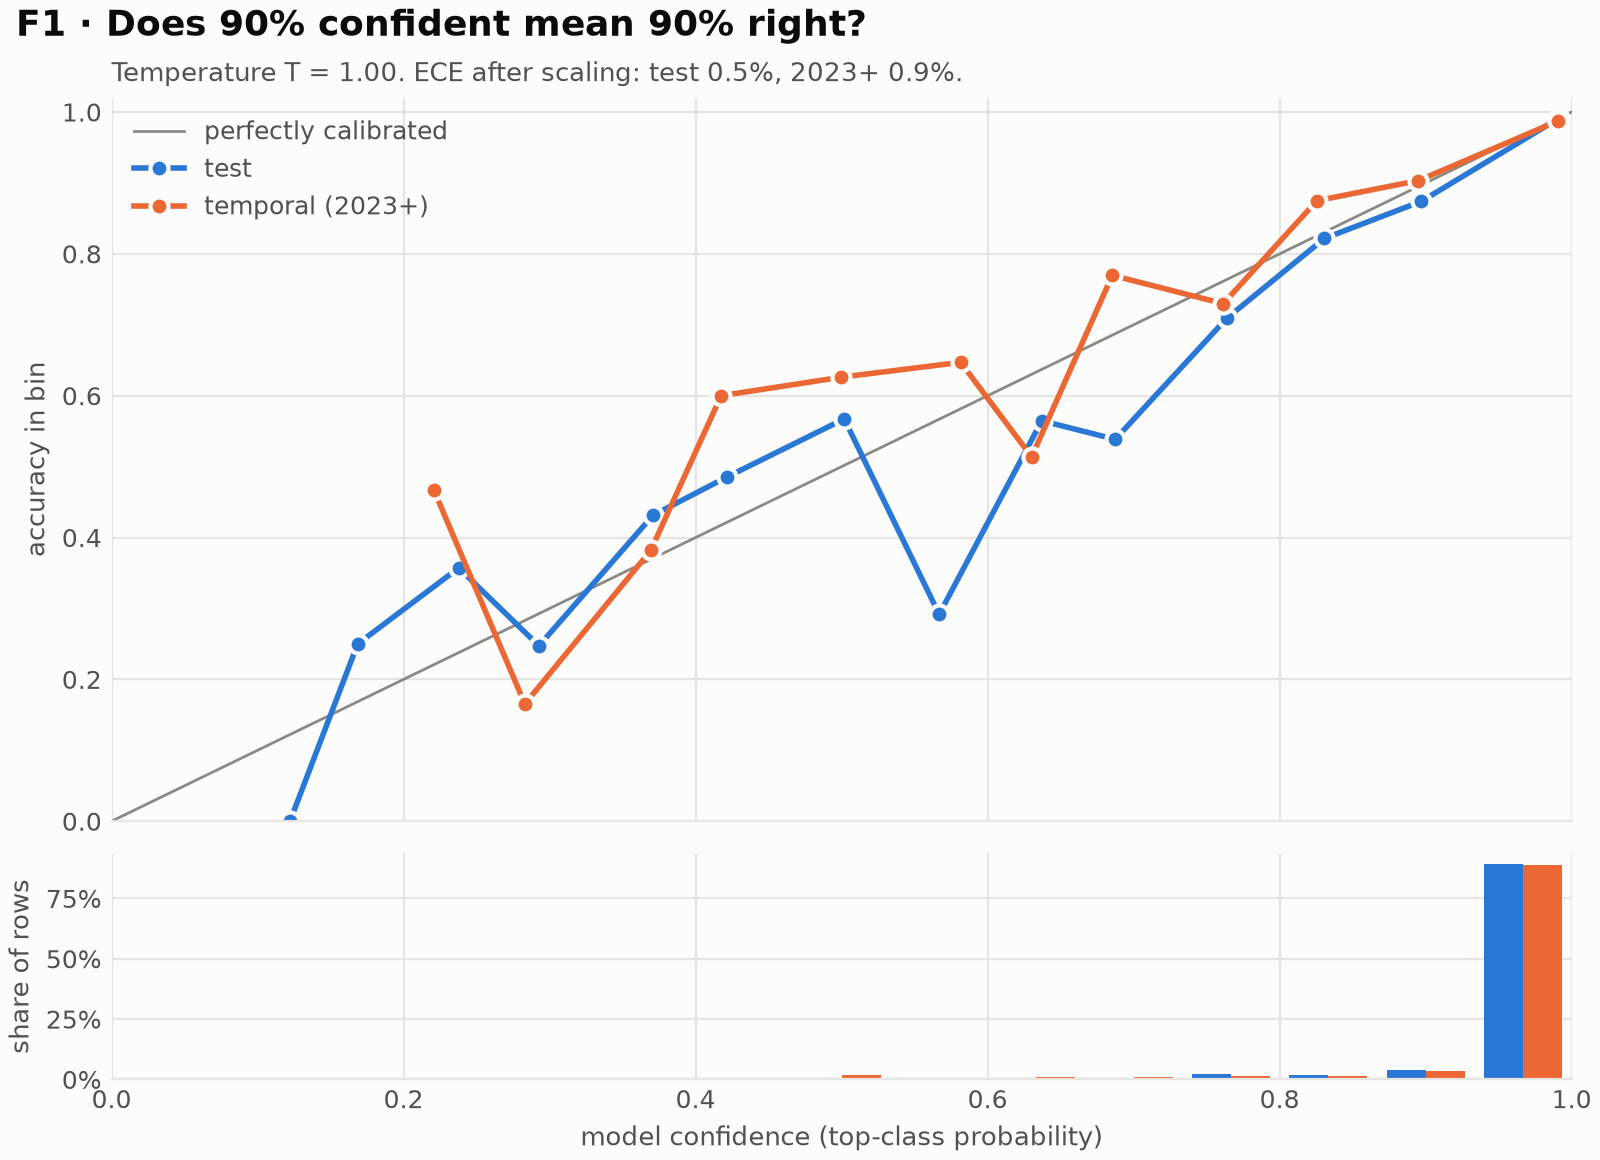

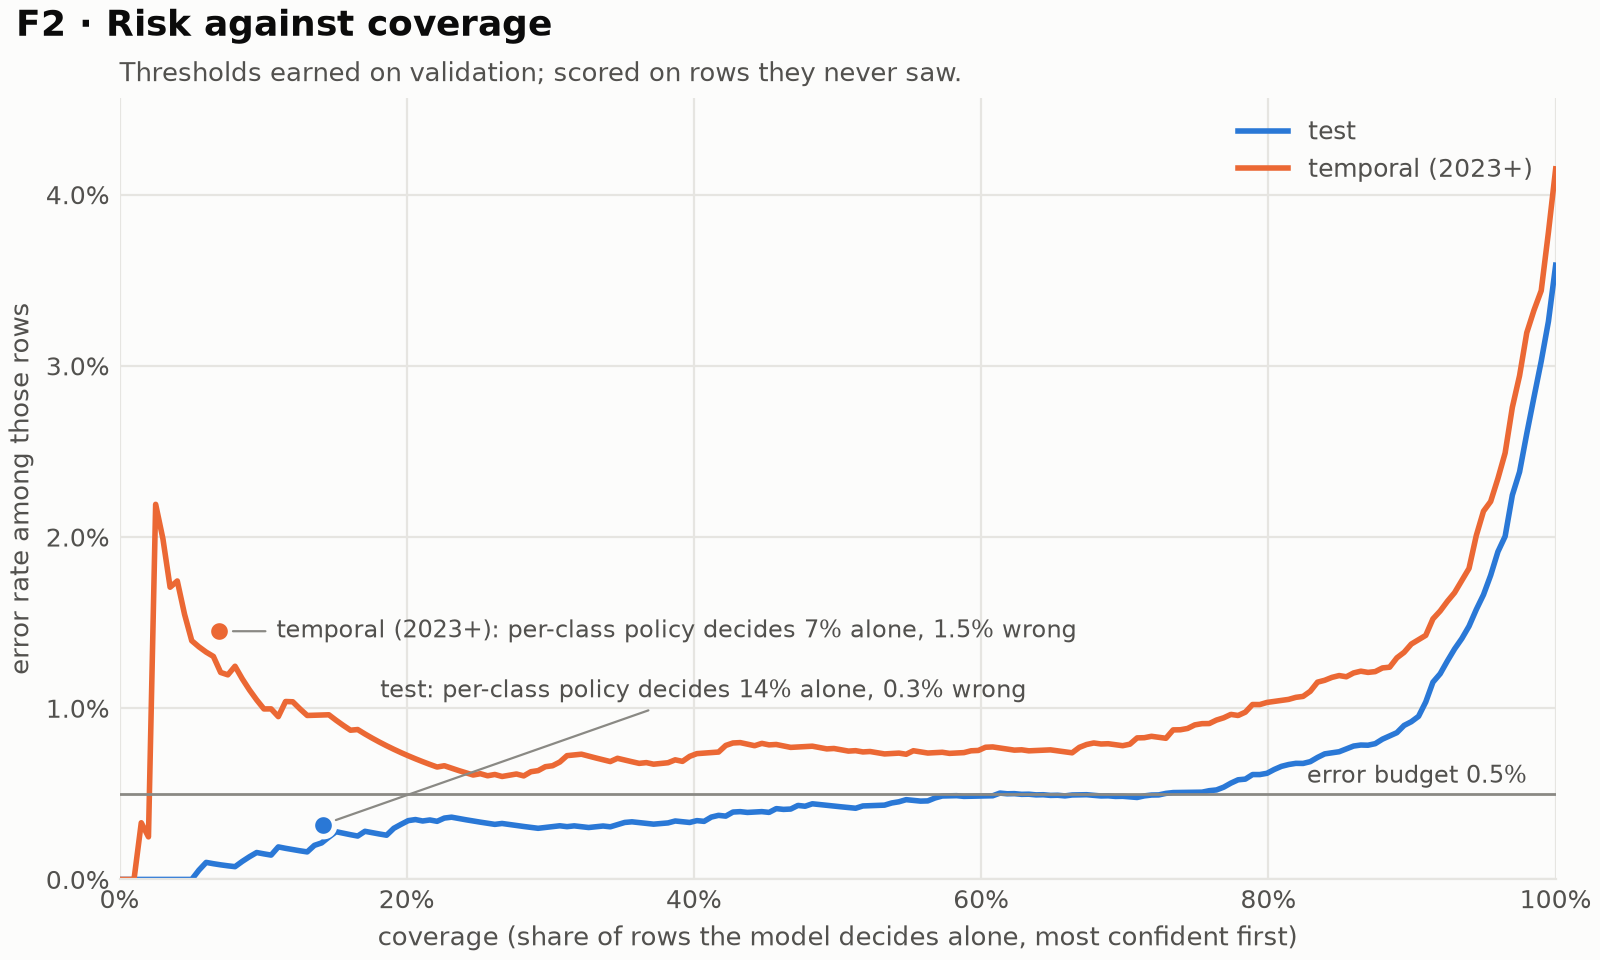

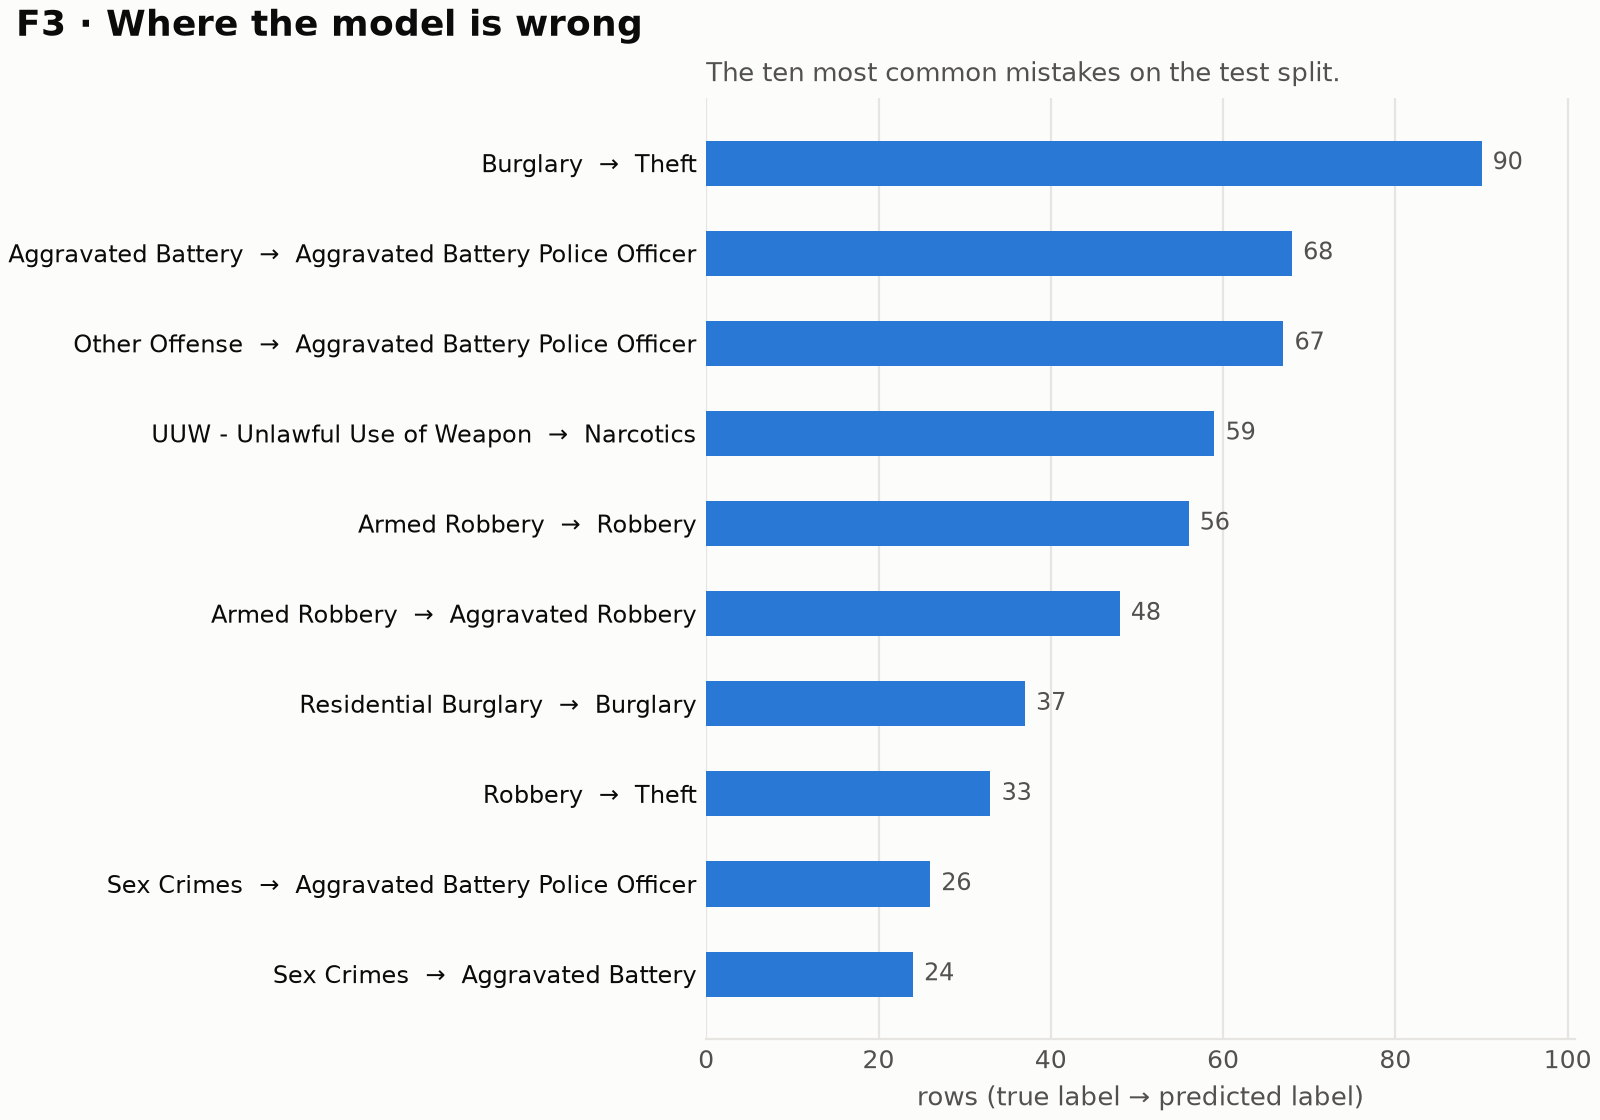

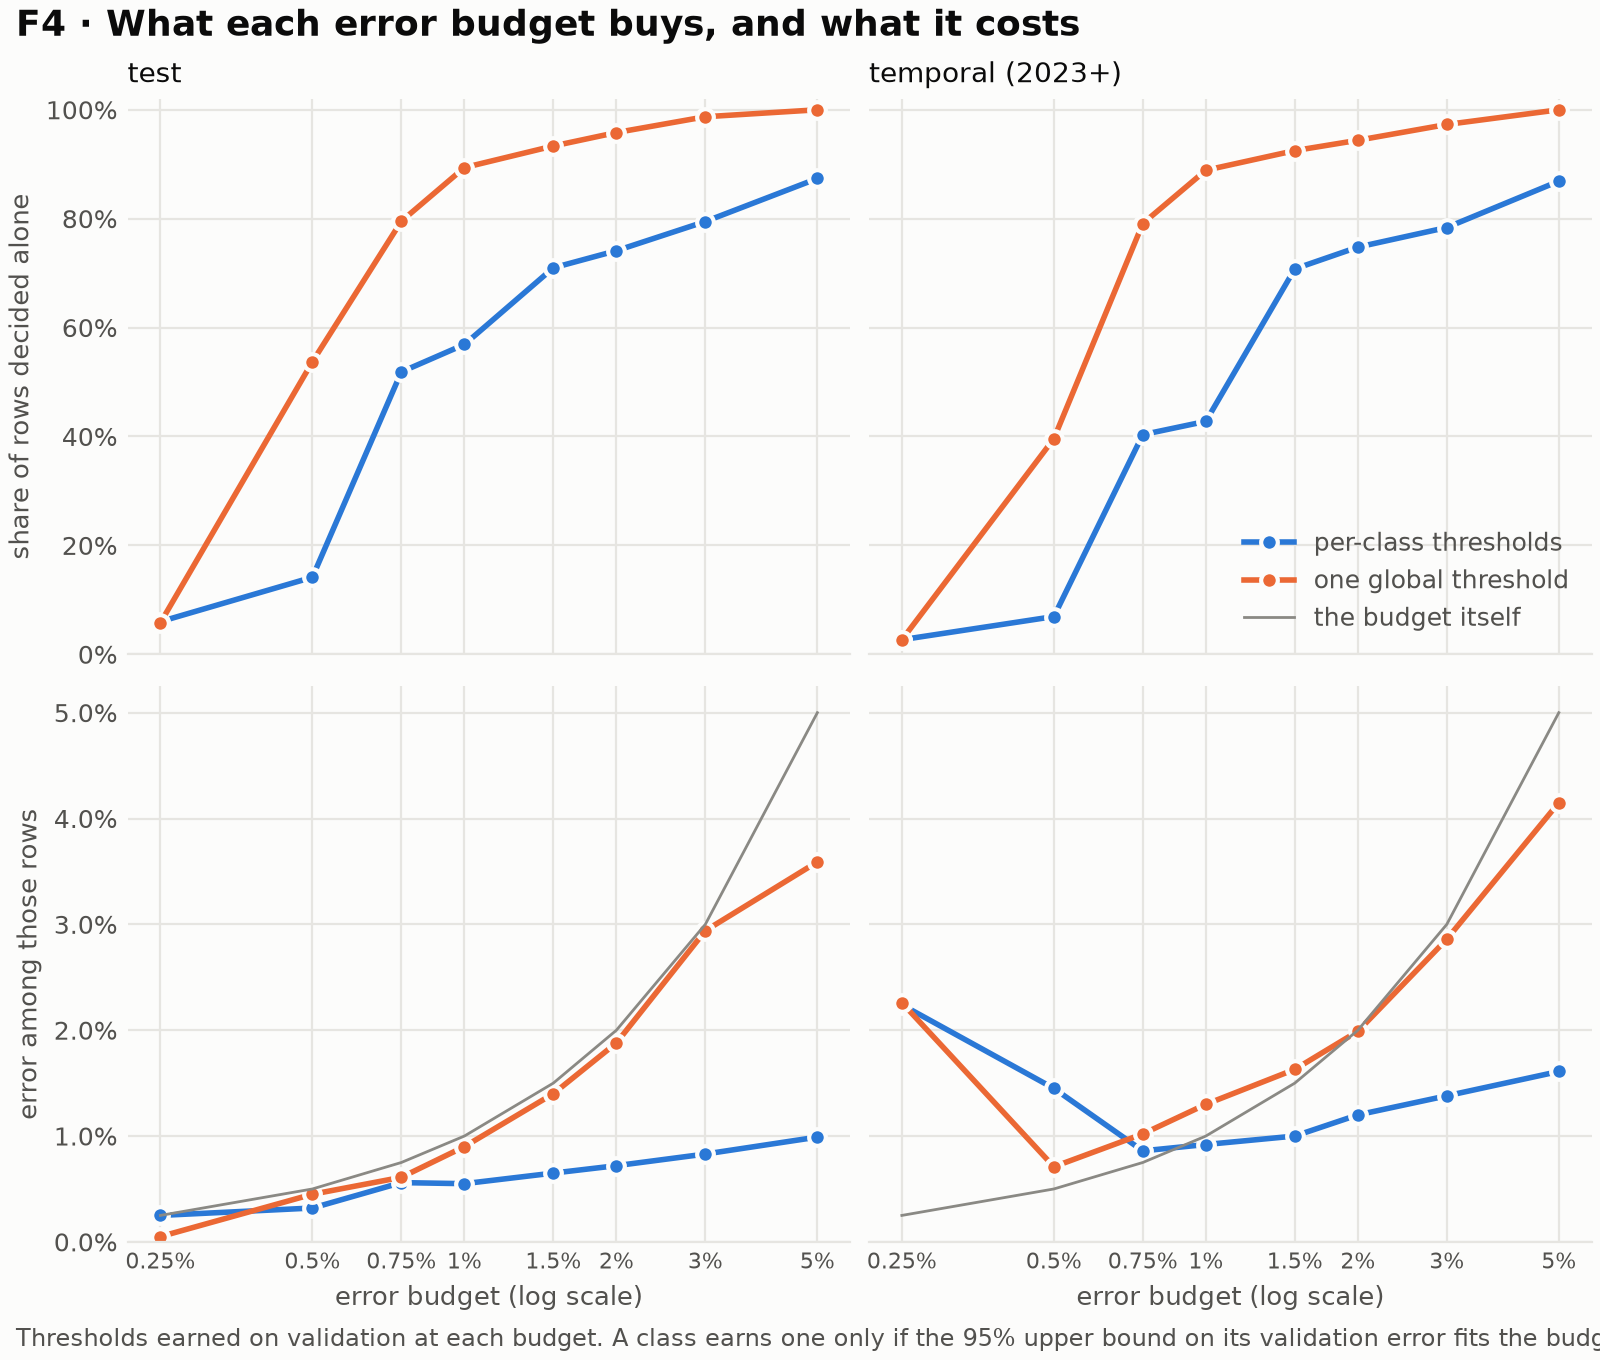

In [31]:
figures = FigureWriter.at(ROOT / 'figures')
summaries = {label: selector.summary(proba[name], labels[name], thresholds, global_tau) for name, label in named.items()}
paths = [
  figures.reliability(
    {label: calibrator.reliability(proba[name], labels[name]) for name, label in named.items()},
    f"Temperature T = {calibrator.temperature:.2f}. ECE after scaling: test {calibration.loc['test', 'ece_after']:.1%}, "
    f"2023+ {calibration.loc['temporal', 'ece_after']:.1%}.",
  ),
  figures.risk_coverage(
    {label: selector.risk_coverage(proba[name], labels[name]) for name, label in named.items()},
    {label: (s['per_class_coverage'], s['per_class_error']) for label, s in summaries.items()},
    selector.error_budget,
    'Thresholds earned on validation; scored on rows they never saw.',
  ),
  figures.top_confusions(confusions, 'The ten most common mistakes on the test split.'),
  figures.budget_sweep(
    sweep,
    tuple(named.values()),
    'Thresholds earned on validation at each budget. A class earns one only if the 95% upper bound on its validation error fits the budget.',
  ),
]
for path in paths:
  display(Image(filename=str(path)))

### 📍 Receipts

⚙️ **What:** temperature, calibration table, thresholds, the abstention summary, the budget sweep and the
top mistakes go into `data/processed/manifest.json`.

🧭 **Why:** same rule as every section: if a number makes it into the article, it lives in the manifest first.

In [32]:
earned = {space.names[c]: round(float(t), 6) for c, t in enumerate(thresholds) if np.isfinite(t)}
RunManifest.read(PROCESSED / 'manifest.json').with_extra(
  calibration={'logits': FEATURED, 'temperature': calibrator.temperature, 'bins': calibrator.bins, 'report': calibration.to_dict('index')},
  abstention={
    'error_budget': selector.error_budget,
    'z': selector.z,
    'thresholds': earned,
    'global_tau': round(float(global_tau), 6),
    'summary': abstention.to_dict('index'),
  },
  budget_sweep=sweep.reset_index().to_dict('records'),
  top_confusions=confusions.to_dict('records'),
  figures=[str(path.relative_to(ROOT)) for path in paths],
).write(PROCESSED / 'manifest.json')

PosixPath('/Users/windfox/src/rapsheet/data/processed/manifest.json')

## 🪪 9 · The model card, and the model's trip to the Hub

⚙️ **What:** `ModelCard` writes `README.md` into the featured model's folder, filled from the manifest and
the model's own metadata: task, labels, data, training config, the headline rows, `T`, the earned
thresholds, failure modes, and what the model is *not* for. Then, behind a switch, `HubPublisher` pushes
the folder to `HUB.model_id` (`<HF_USERNAME>/rapsheet-legal-bert-small`).

🧭 **Why generate it:** a card typed by hand drifts from the notebook the first time anything is rerun.
This one can't: if a number is on the card, it came out of `manifest.json`.

🧭 **Why the card leads with what the model isn't:** anyone can download the weights. The card is the one
document that travels with them, so *not a screening tool, not for any decision about a person* goes at
the top, where the Hub renders it first.

In [33]:
featured_model, featured_dir = (tempered, tempered_dir) if FEATURED == 'logits-tempered' else (encoder, encoder_dir)
card = ModelCard(repo_id=HUB.model_id, dataset_repo=HUB.dataset_id)
card_path = card.write(featured_dir, RunManifest.read(PROCESSED / 'manifest.json'), featured_model.name)
print(f'{card_path.relative_to(ROOT)} — {len(card_path.read_text().split()):,} words')
display(Markdown(card_path.read_text().split('---', 2)[2]))

models/rapsheet-legal-bert-small-tempered/README.md — 1,035 words




# rapsheet · legal-bert-small, calibrated and abstaining

**A reference implementation of a methodology for calibrated, abstaining classification of charge
text. Not a screening tool, and not for any decision about a person.**

Reads one county's charge titles (`AGG UUW/VEH/PREV CONVICTION`) together with the statute citation
(`720 ILCS 5/24-1.6`) and predicts the prosecutor's own offense category. The point of the model is
not the category; it is the calibrated confidence next to it, and the per-class threshold that
decides which calls it may make alone. The method, the code and every number here live in the
[rapsheet](https://github.com/tangledpath/rapsheet) package and its notebook; the write-up is
[the article](https://git-steven.github.io/architecture/ai/ml/reading-the-rap-sheet/).

## Task and labels

- **Input:** a sentence pair, `[CLS] title [SEP] chapter ILCS act/section [SEP]`
  (`include_statute=True`), tokenized to 64 tokens.
- **Output:** 68 training labels: 67 named offense categories plus `(rare, folded)`, the
  bucket for categories with fewer than 20 training rows. Label order is fixed in
  `rapsheet_encoder.json` and in `config.json`'s `id2label`.
- **Confidence:** softmax of the logits after the class-tempering logit adjustment saved alongside the weights. Temperature scaling
  fitted on validation gives **T = 1.002**; the calibrated probabilities feed the abstention
  thresholds below.

## Data

- Cook County State's Attorney, *Dispositions* (`apwk-dzx8`, https://datacatalog.cookcountyil.gov/d/apwk-dzx8), public domain.
  Retrieved 2026-10-20: 1,080,014 charge-level rows, de-identified by the publisher.
  The publisher stopped maintaining the table in December 2024; the portal's latest row timestamp is
  `2026-04-02T14:58:19.622Z`.
- Splits (grouped by case, stratified by label, seed 42; `temporal` = received on or
  after 2023-01-01): temporal 19,973, test 33,305, train 266,439, val 33,305. Published without identifiers as
  [`terracoil/rapsheet-charge-titles`](https://huggingface.co/datasets/terracoil/rapsheet-charge-titles).
- Never pulled, never features: `race`, `gender`, `age_at_incident`, `judge`, `incident_city`,
  `law_enforcement_agency`, `unit`; `offense_category` (the pre-update label) dropped as leakage.
- `PROMIS Conversion` rows (9,824 rows, a legacy-system flag, not an offense) are never trained
  on; the 4,833 rows whose titles never appear with a real label are a label-free drift probe.

## Training

Base model [`nlpaueb/legal-bert-small-uncased`](https://huggingface.co/nlpaueb/legal-bert-small-uncased) with a fresh classification head.
Plain-torch loop: 3 epochs of 50,000 draws of distinct (title, citation) inputs,
batch 64, AdamW (lr 5e-05, weight decay 0.01), linear warm-up
(0.06) and decay, gradient clipping at 1.0, seed 42. Draws are
class-tempered with exponent 0.5 (each class's share of draws is proportional to
`rows ** 0.5`); the matching logit adjustment is added back at prediction time, so the
probabilities answer for the real class frequencies. The epoch with the lowest validation
negative log-likelihood is kept.

| epoch | train loss | val NLL | val accuracy |
|---|---|---|---|
| 1 | 1.1934 | 0.1864 | 0.9608 |
| 2 | 0.3656 | 0.1697 | 0.9632 |
| 3 | 0.3340 | 0.1631 | 0.9640 |

Package git SHA at processing time: `50c4395`. Hardware: Darwin arm64 (arm) / Python 3.13.16.

## Evaluation

Scored by the same function as every baseline, on the stratified test split and the 2023+ split.
*Rare-class recall* averages categories with fewer than 500 training rows; *rare-title accuracy*
covers titles seen fewer than five times in training.

| model | split | accuracy | macro-F1 | rare-class recall | rare-title accuracy |
|---|---|---|---|---|---|
| legal-bert-small (title + statute, class-tempered 0.5) | test | 0.9641 | 0.8802 | 0.8522 | 0.6474 |
| legal-bert-small (title + statute, class-tempered 0.5) | temporal | 0.9585 | 0.8879 | 0.8657 | 0.6454 |
| statute rules | test | 0.9643 | 0.8607 | 0.7799 | 0.6368 |
| statute rules | temporal | 0.9604 | 0.8383 | 0.7354 | 0.6312 |

### Calibration (temperature T = 1.002, 15 bins)

| split | ECE before | ECE after | NLL before | NLL after | mean confidence after |
|---|---|---|---|---|---|
| temporal | 0.94% | 0.94% | 0.2014 | 0.2013 | 0.9593 |
| test | 0.49% | 0.48% | 0.1641 | 0.1641 | 0.9676 |
| val | 0.39% | 0.37% | 0.1631 | 0.1631 | 0.9673 |

### Earned autonomy at a 0.50% error budget

A class earns a threshold only if the upper end of a one-sided Wilson interval (z = 1.645) on its
validation errors stays within the budget. 3 of 68 classes earn one:

| class | τ |
|---|---|
| Aggravated DUI | 0.6362 |
| Narcotics | 0.9968 |
| Retail Theft | 0.9931 |

| split | decided alone (per-class τ) | error among those | decided alone (one global τ = 0.9936) | error |
|---|---|---|---|---|
| promis_unseen | 3.87% | n/a | 8.44% | n/a |
| temporal | 6.93% | 1.45% | 39.60% | 0.71% |
| test | 14.15% | 0.32% | 53.72% | 0.45% |
| val | 14.18% | 0.11% | 54.00% | 0.40% |

Thresholds are earned on validation and scored on rows they never saw. On the 2023+ split the
per-class policy runs over budget: the thresholds need an owner and a review date, not just a value.

## Known failure modes

- **Label noise.** The category describes the case; the title describes the charge. Around 3% of
  rows carry a label their input cannot predict, which caps every model near 96.7%.
- **Temporal drift.** Thresholds earned before 2023 do not hold on 2023+ cases.
- **Single jurisdiction.** One county's spelling of charges. The legacy `PROMIS` dialect shows what
  happens on text the model has never seen: confidence stays high (mean top-class confidence
  0.849 on the probe).
- **Small classes.** Categories with few validation rows cannot earn a threshold at this budget,
  whatever their recall.

## Intended use and out of scope

Intended: studying calibration, abstention and the separation of policy from weights on public
data; reproducing the article. **Out of scope: any decision about a person**, screening,
re-identification, or use on records from another jurisdiction without re-evaluation.

## Reproduce

```bash
git clone https://github.com/tangledpath/rapsheet && cd rapsheet
poetry install --with dev && poetry run rapsheet-pull
poetry run jupyter lab notebooks/reading_the_rap_sheet.ipynb   # Restart & Run All
```

```python
from rapsheet.encoder import EncoderClassifier
model = EncoderClassifier.load('path/to/this/repo')   # after `hf download terracoil/rapsheet-legal-bert-small`
probabilities = model.predict_proba(frame)             # columns in LabelSpace order
```

License: the weights derive from `nlpaueb/legal-bert-small-uncased` (CC BY-SA 4.0) and carry the same terms; the
rapsheet code is MIT.


### 🛰️ Publish the model (on purpose)

⚙️ **What:** the same guarded push as the dataset, with `repo_type='model'`. About 140 MB of weights plus
the tokenizer, `config.json`, `rapsheet_encoder.json` and the card.

🧭 **Why a second switch:** publishing the data and publishing the model are separate decisions, and a
switch you flipped yesterday shouldn't publish something new today.

From a shell: `poetry run rapsheet-publish model --yes` (add `--folder` for a different model folder).

In [34]:
PUBLISH_MODEL = False  # flip on purpose: this makes the fine-tuned model public on the Hugging Face Hub

if PUBLISH_MODEL:
  publisher = HubPublisher()
  print('publishing as', publisher.identity(), 'to', HUB.model_url)
  print(publisher.publish(
    featured_dir,
    HUB.model_id,
    repo_type='model',
    message=f"{featured_model.name}; {processed_manifest.retrieved_at[:10]} pull (git {RunManifest.current_git_sha()})",
  ))
else:
  print(f'PUBLISH_MODEL is False; {HUB.model_id} was not touched.')

publishing as terracoil
https://huggingface.co/terracoil/rapsheet-legal-bert-small


---
🧬 **Next:** the model card, and the model's own trip to the Hub (`repo_type='model'`), guarded by the same
`PUBLISH` switch as the dataset.

## 📦 Details: what's under the hood

In [35]:
from dataclasses import asdict, dataclass
from importlib.metadata import distributions
from platform import python_version
from IPython.display import Markdown, display

@dataclass
class PythonTool:
  """Dataclass for containing package/tool information: One row of the bill of materials: what a package does, why it's here, and which version ran."""
  what: str
  why: str
  version: str|None = None

NA = "n/a"

imports: dict[str, PythonTool] = {
  'Python standard library': PythonTool( what='`dataclasses`, `pathlib`, `json`, `logging`, `argparse`, `subprocess`, `platform`, `types`', why=""'`@dataclass(frozen=True)` is the immutability story; `subprocess` and `platform` stamp the git SHA and hardware into the manifest'),
  'pandas':PythonTool( what='DataFrames', why='Load → refuse → clean → split is a chain of frame transforms; `DataFrame.attrs` carries the cleaning counts along to the manifest'),
  'pyarrow':PythonTool( 'The columnar engine behind pandas\' parquet I/O', 'Caches the million-row pull in about 35 MB and reloads it in seconds, so the portal only gets asked once'),
  'numpy': PythonTool( 'Arrays', 'Index bookkeeping for the folds, and every probability matrix the baselines hand back'),
  'PyYAML': PythonTool( 'YAML parser', 'Reads `disposition_map.yaml`, the hand-written policy file, with `safe_load`, because a policy file shouldn\'t be able to run code'),
  'requests': PythonTool( 'HTTP client', 'Talks to the SODA API: paging, the app-token header, retries with backoff'),
  'scikit-learn': PythonTool('Classical ML toolkit', '`StratifiedGroupKFold` for leakage-free splits, `TfidfVectorizer` + `LogisticRegression` for the bag-of-n-grams baseline, and `f1_score` for the headline table'),
  'torch': PythonTool( 'Tensors, autograd, Apple-silicon GPU (MPS)', 'Runs the fine-tune (AdamW, a linear warm-up/decay schedule, weighted draws via `torch.multinomial`) and, next, the one-parameter temperature fit'),
  'transformers': PythonTool( 'Pretrained models and tokenizers', 'Supplies `legal-bert-small` and its tokenizer. The training loop itself is plain torch, because the weighted draw is the part worth seeing'),
  'huggingface_hub': PythonTool( 'Client for the Hugging Face Hub', 'Creates the dataset repo and uploads the snapshot and the model). Nothing is pushed unless `PUBLISH = True`.'),
  'matplotlib': PythonTool( 'Plotting library', 'Draws F1–F4 for the article through `matplotlib.figure.Figure` objects, so no global pyplot state leaks between cells'),
}

# PACKAGES: dict[str, PythonPackage] = {}
tools: dict[str, PythonTool] = {
  'Jupyter': PythonTool('Notebook server and UI', 'You\'re looking at it'),
  'Poetry': PythonTool('Dependency and virtualenv manager', 'Dependencies, the virtualenv, and the `rapsheet-pull` console script'),
  'poetry-dotenv-plugin': PythonTool('Poetry plugin that loads `.env` into the environment', 'Loads `SODA_APP_TOKEN` from `.env`, so the token never lands in a notebook or a commit'),
  'pytest': PythonTool( 'Test runner', 'Tests run on a synthetic fixture with the real column names, so the pipeline worked before the real data arrived'),
  'ruff': PythonTool( 'Linter and formatter', 'Lint and format: two-space indent, single quotes, 100 columns'),
}

# Poetry and its plugin live outside the venv, so they have no version to report from here.
versions: dict[str, str] = {
  **{d.metadata['Name'].lower().replace('_', '-'): d.version for d in distributions()},
  'python standard library': python_version(),
  'poetry': 'n/a',
  'poetry-dotenv-plugin': 'n/a',
}

for k,package in imports.items():
  package.version = versions.get(k.lower().replace('_', '-'), NA)

for k,tool in tools.items():
  tool.version = versions.get(k.lower().replace('_', '-'), NA)


df_imports = pd.DataFrame.from_dict({f"`{k}`": asdict(v) for k, v in imports.items()}, orient='index')
df_tools = pd.DataFrame.from_dict({f"{k}": asdict(v) for k, v in tools.items()}, orient='index')
display(Markdown("## 📦 Imports"))
display(Markdown('_Every package the code imports directly, what it does, and why it earned a place. Versions are read from the environment this notebook just ran in, because "it worked on my machine" is only useful if you know which machine._'))
display(Markdown(df_imports.to_markdown()))
display(Markdown("## 🛠️ Tools"))
display(Markdown("_Around the code (tools, not imports)_"))
display(Markdown(df_tools.to_markdown()))

## 📦 Imports

_Every package the code imports directly, what it does, and why it earned a place. Versions are read from the environment this notebook just ran in, because "it worked on my machine" is only useful if you know which machine._

|                           | what                                                                                       | why                                                                                                                                                             | version   |
|:--------------------------|:-------------------------------------------------------------------------------------------|:----------------------------------------------------------------------------------------------------------------------------------------------------------------|:----------|
| `Python standard library` | `dataclasses`, `pathlib`, `json`, `logging`, `argparse`, `subprocess`, `platform`, `types` | `@dataclass(frozen=True)` is the immutability story; `subprocess` and `platform` stamp the git SHA and hardware into the manifest                               | 3.13.16   |
| `pandas`                  | DataFrames                                                                                 | Load → refuse → clean → split is a chain of frame transforms; `DataFrame.attrs` carries the cleaning counts along to the manifest                               | 3.0.6     |
| `pyarrow`                 | The columnar engine behind pandas' parquet I/O                                             | Caches the million-row pull in about 35 MB and reloads it in seconds, so the portal only gets asked once                                                        | 26.0.0    |
| `numpy`                   | Arrays                                                                                     | Index bookkeeping for the folds, and every probability matrix the baselines hand back                                                                           | 2.5.4     |
| `PyYAML`                  | YAML parser                                                                                | Reads `disposition_map.yaml`, the hand-written policy file, with `safe_load`, because a policy file shouldn't be able to run code                               | 6.0.3     |
| `requests`                | HTTP client                                                                                | Talks to the SODA API: paging, the app-token header, retries with backoff                                                                                       | 2.34.2    |
| `scikit-learn`            | Classical ML toolkit                                                                       | `StratifiedGroupKFold` for leakage-free splits, `TfidfVectorizer` + `LogisticRegression` for the bag-of-n-grams baseline, and `f1_score` for the headline table | 1.9.1     |
| `torch`                   | Tensors, autograd, Apple-silicon GPU (MPS)                                                 | Runs the fine-tune (AdamW, a linear warm-up/decay schedule, weighted draws via `torch.multinomial`) and, next, the one-parameter temperature fit                | 2.14.1    |
| `transformers`            | Pretrained models and tokenizers                                                           | Supplies `legal-bert-small` and its tokenizer. The training loop itself is plain torch, because the weighted draw is the part worth seeing                      | 5.20.2    |
| `huggingface_hub`         | Client for the Hugging Face Hub                                                            | Creates the dataset repo and uploads the snapshot (and, tomorrow, the model). Nothing is pushed unless `PUBLISH = True`.                                        | 2.2.0     |
| `matplotlib`              | Plotting library                                                                           | Draws F1–F4 for the article through `matplotlib.figure.Figure` objects, so no global pyplot state leaks between cells                                           | 3.11.2    |

## 🛠️ Tools

_Around the code (tools, not imports)_

|                      | what                                                 | why                                                                                                              | version   |
|:---------------------|:-----------------------------------------------------|:-----------------------------------------------------------------------------------------------------------------|:----------|
| Jupyter              | Notebook server and UI                               | You're looking at it                                                                                             | 1.1.1     |
| Poetry               | Dependency and virtualenv manager                    | Dependencies, the virtualenv, and the `rapsheet-pull` console script                                             | n/a       |
| poetry-dotenv-plugin | Poetry plugin that loads `.env` into the environment | Loads `SODA_APP_TOKEN` from `.env`, so the token never lands in a notebook or a commit                           | n/a       |
| pytest               | Test runner                                          | Tests run on a synthetic fixture with the real column names, so the pipeline worked before the real data arrived | 8.4.2     |
| ruff                 | Linter and formatter                                 | Lint and format: two-space indent, single quotes, 100 columns                                                    | 0.17.1    |